# CNN validation performance

Train a CNN with learning rate **0.1**, using the same `CNNConfig()`, data split, and training defaults as `learning_rate.ipynb`. Save the final validation predictions and epoch metrics for later analysis.

In [7]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

# Support running from the project root or the notebook directory.
project_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src" / "sfs" / "training.py").is_file()
)
if str(project_root / "src") not in sys.path:
    sys.path.insert(0, str(project_root / "src"))

from sfs.config import CNNConfig
from sfs.models import make_CNN
from sfs.training import create_training_data, train

In [8]:
training_data = pd.read_csv(project_root / "data" / "train.csv")
X = training_data.drop(columns=["label"])
y = training_data["label"]
Data = create_training_data(X, y)

output_dir = project_root / "results" / "performance"
output_dir.mkdir(parents=True, exist_ok=True)
predictions_path = output_dir / "cnn_lr_0.1_validation_predictions.csv"
history_path = output_dir / "cnn_lr_0.1_history.csv"

In [9]:
cnn_conf = CNNConfig()
model = make_CNN(cnn_conf)
history = train(model, Data, learning_rate=0.01, predictions_path=predictions_path)
history.to_csv(history_path, index=False)
display(history)
print(f"Validation predictions: {predictions_path}")
print(f"Training history: {history_path}")

,epoch,train_loss,val_loss,val_accuracy
0,1,0.211117,0.097942,0.970595
1,2,0.075770,0.091217,0.972857
2,3,0.055072,0.088992,0.974762
3,4,0.043087,0.084621,0.978095
4,5,0.035918,0.094710,0.974881
5,6,0.029205,0.106338,0.971548
6,7,0.022781,0.100795,0.974881
7,8,0.020521,0.129733,0.973452
8,9,0.018438,0.119797,0.973690
9,10,0.016664,0.131402,0.975000


Validation predictions: /Users/admin/Desktop/mini_projects/digit_recognition/results/performance/cnn_lr_0.1_validation_predictions.csv
Training history: /Users/admin/Desktop/mini_projects/digit_recognition/results/performance/cnn_lr_0.1_history.csv


## Accuracy per digit

Analyze the saved predictions from the final epoch. Accuracy for a digit is the fraction of validation examples **whose true label is that digit** that were classified correctly (class recall). The CSV also preserves original row indices and class probabilities for further analysis.

In [10]:
validation = pd.read_csv(predictions_path)
y_true = validation["true_label"]
y_pred = validation["predicted_label"]
digits = list(range(10))

print(f"Overall validation accuracy: {accuracy_score(y_true, y_pred):.2%}")
accuracy_per_digit = (
    validation.assign(correct=y_true.eq(y_pred))
    .groupby("true_label")["correct"]
    .agg(n_examples="count", n_correct="sum", accuracy="mean")
    .reindex(digits)
    .rename_axis("digit")
)
display(accuracy_per_digit.style.format({"accuracy": "{:.2%}"}))

Overall validation accuracy: 97.50%


,n_examples,n_correct,accuracy
digit,,,
0,827,814,98.43%
1,937,927,98.93%
2,835,823,98.56%
3,870,832,95.63%
4,814,790,97.05%
5,759,739,97.36%
6,827,814,98.43%
7,880,837,95.11%
8,813,800,98.40%


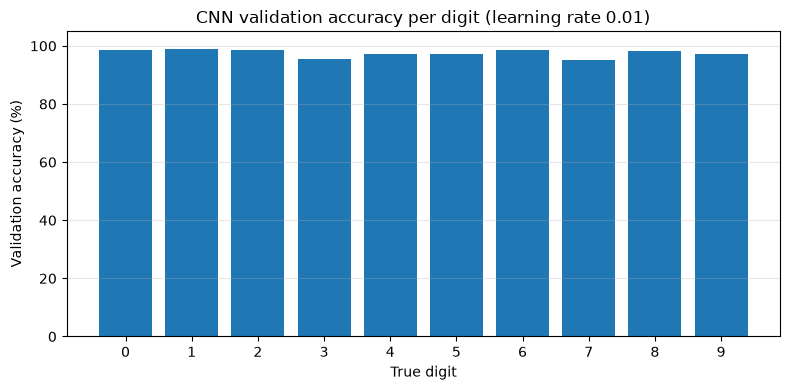

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(accuracy_per_digit.index, accuracy_per_digit["accuracy"] * 100)
ax.set_xticks(digits)
ax.set_ylim(0, 105)
ax.set_xlabel("True digit")
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("CNN validation accuracy per digit (learning rate 0.01)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## Confusion matrix

Rows show true digits; columns show predicted digits. Each cell counts validation examples. Correct predictions lie on the diagonal.

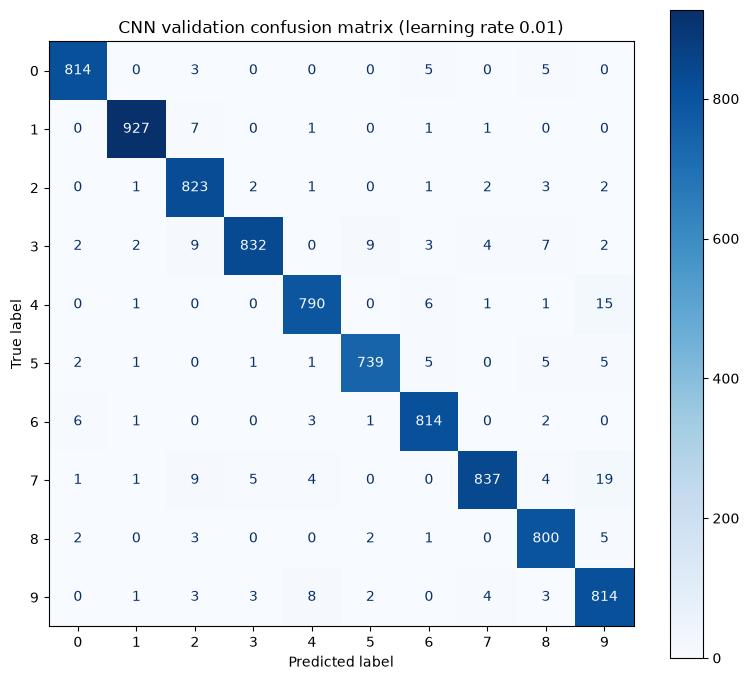

In [12]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=digits, display_labels=digits,
    cmap="Blues", values_format="d", ax=ax,
)
ax.set_title("CNN validation confusion matrix (learning rate 0.01)")
fig.tight_layout()
plt.show()